# 6 — Advanced Small-Data Neural Architectures: Gated/Interaction Residual MLP & Attention-Pooling over FinBERT Chunks

**Motivation.** In `05-MLP-updated-v2.ipynb`, a tuned, refitted residual MLP (`ResidualTextNet`) with Huber loss outperformed both bag-of-words Ridge and FinBERT Ridge. However, two structural limitations remained:
1. **Strictly additive fusion:** `ResidualTextNet` computes $\hat{z}_{\text{after}} = (a z_{\text{before}} + b) + f_{\text{text}}(\mathbf{x})$, so the text branch cannot condition its correction on whether a company is already high- or low-volatility.
2. **Diluted long-document representations:** Standard FinBERT truncates at 512 tokens or mean-pools across chunks, diluting a single critical risk paragraph (e.g., going-concern warning or debt covenant breach) inside pages of boilerplate Item 7 text.

This notebook implements two parameter-efficient neural architectures designed specifically for this small-data regime (~7.5k–14k training filings per rolling window):
1. **Gated / Interaction Residual MLP (`GatedInteractionMLP`):** Conditions the text correction on $z_{\text{before}}$ and modulates it with a learned sigmoid gate $g(\mathbf{x}, z_{\text{before}}) \in (0, 1)$, evaluated on both Bag-of-Words TF-IDF and document-level FinBERT embeddings.
2. **Attention-Pooling over Frozen FinBERT Chunks (`FinBERTAttentionNet`):** Keeps FinBERT frozen and learns a lightweight masked additive attention layer over 512-token chunks—giving the model the ability to focus on high-risk passages while providing chunk-level explainability.

Both models preserve the exact temporal splits, leakage-free feature scaling, isolated weight decay, Huber loss, full-window refit, and `scoring.evaluate` protocol from Notebooks `02` and `05`.

## 6.1 — Setup, Data Loading & Alignment

In [3]:
import gc
import gzip
import json
import os
import pickle
import sys
import tarfile
import time
import urllib.request
from pathlib import Path
from types import SimpleNamespace

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.sparse as sp
from sklearn.feature_extraction.text import TfidfTransformer
import torch
from torch import nn

ROOT = Path("..")
PROCESSED = ROOT / "data" / "processed"
OUTPUT = ROOT / "data" / "output"
BOW_DIR = PROCESSED / "bow"
kogan_dir = ROOT / "data" / "raw" / "kogan"
edgar_dir = PROCESSED / "edgar_matched"
KOGAN_URL = "https://www.cs.cmu.edu/~ark/10K/data/"

sys.path.insert(0, str(ROOT / "Alex"))
import scoring

# --- configuration -------------------------------------------------------------------------------
MAIN_WINDOW = "paper"
N_WORDS = 5000
MIN_DF = 50
HIDDEN = 32
ATTN_DIM = 64                                  # hidden size of the lightweight chunk attention layer
DROPOUT = 0.5
LR = 1e-3
WEIGHT_DECAY = 5e-2
BATCH = 256
MAX_EPOCHS = 40
PATIENCE = 5
HUBER_DELTA = 1.0
SEEDS = [0, 1, 2]
VERY_LOW = -5.0

# --- optional overrides for FinBERT doc & chunk embeddings ---------------------------------------
FINBERT_DOC_PATH = None                        # e.g. PROCESSED / "finbert_item7.npy"
FINBERT_DOC_KEY = None                         # e.g. key inside data.pkl
CHUNK_EMB_PATH = PROCESSED / "finbert_item7_chunks.npz"
EXTRACT_CHUNKS_IF_MISSING = False              # set True on GPU/Colab to extract 512-token FinBERT chunks
MAX_CHUNKS = 16                                # up to 16 x 512-token chunks per Item 7 (~8,192 tokens)
FINBERT_MODEL_NAME = "ProsusAI/finbert"

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Device: {device} | CPU threads: {torch.get_num_threads()} / {os.cpu_count()}")

Device: cpu | CPU threads: 8 / 16


In [5]:
with open(PROCESSED / "data.pkl", "rb") as f:
    d = pickle.load(f)
df = scoring.frame(d)
y = df["logvol_after"].to_numpy()
prev = df["logvol_before"].to_numpy()
year_arr = df["year"].to_numpy()
keys = df["key"].tolist()
print(f"{len(df):,} reports, {df.year.min()}-{df.year.max()}")

def as_mask(m):
    m = np.asarray(m)
    if m.dtype == bool:
        return m
    out = np.zeros(len(df), dtype=bool)
    out[m] = True
    return out

# Verify split alignment against 02
copy_vs_line = scoring.evaluate(df, scoring.predict_copy, name="copy last year")
alex_file = OUTPUT / "alex-02-ridge-results.csv"
alex = pd.read_csv(alex_file) if alex_file.exists() else None
v2_file = OUTPUT / "louis-05-wordcount-v2-results.csv"
prev_mlp_res = pd.read_csv(v2_file) if v2_file.exists() else None

if alex is not None:
    keys_ = ["window", "test_year"]
    theirs = alex[alex.model == "copy last year"].set_index(keys_)[["test_reports", "mse", "baseline_mse"]].sort_index()
    ours = copy_vs_line.set_index(keys_)[["test_reports", "mse", "baseline_mse"]].sort_index()
    pd.testing.assert_frame_equal(ours, theirs, check_dtype=False)
    print("Aligned with alex-02-ridge-results.csv.")

# --- Load cached BoW candidate counts from Notebook 05 -------------------------------------------
meta = pd.read_csv(PROCESSED / "dataset.csv", parse_dates=["date"]).drop(columns="item7_source", errors="ignore")
src_file = PROCESSED / "item7_source.csv"
USE_EDGAR = src_file.exists() and edgar_dir.exists() and any(edgar_dir.glob("*.jsonl.gz"))
TEXT_TAG = "edgar" if USE_EDGAR else "kogan"
if USE_EDGAR:
    meta = meta.merge(pd.read_csv(src_file)[["key", "item7_source"]], on="key", how="inner")
else:
    meta["item7_source"] = "kogan"
data = df[["key"]].merge(meta, on="key", how="left", validate="one_to_one")

cache_npz, cache_json = BOW_DIR / f"candidates_{TEXT_TAG}.npz", BOW_DIR / f"candidates_{TEXT_TAG}.json"
assert cache_npz.exists() and cache_json.exists(), (
    f"Run Notebook 05 first to build {cache_npz.name}, or point BOW_DIR to your cached counts."
)
cached = json.loads(cache_json.read_text())
assert cached["keys"] == keys, "Cached BoW counts do not match data.pkl report keys."
X_counts = sp.load_npz(cache_npz).tocsr()
vocab = np.array(cached["vocab"])
print(f"Loaded cached BoW counts: {X_counts.shape}")

# --- Auto-detect document-level FinBERT embeddings -----------------------------------------------
def load_finbert_doc(d_obj, n_rows, processed_dir, explicit_path=None, explicit_key=None):
    def _extract_2d(arr):
        try:
            arr = np.asarray(arr)
        except (ValueError, TypeError):
            return None
        if arr.ndim == 2 and arr.shape[0] == n_rows and arr.shape[1] >= 64 and np.issubdtype(arr.dtype, np.number):
            return arr.astype(np.float32)
        return None
    if explicit_path is not None:
        p = Path(explicit_path)
        if p.exists() and p.suffix == ".npy":
            emb = _extract_2d(np.load(p))
            if emb is not None:
                return emb, f"file:{p.name}"
    if explicit_key is not None and isinstance(d_obj, dict) and explicit_key in d_obj:
        emb = _extract_2d(d_obj[explicit_key])
        if emb is not None:
            return emb, f"data.pkl[{explicit_key!r}]"
    if isinstance(d_obj, dict):
        cands = []
        for k, v in d_obj.items():
            emb = _extract_2d(v)
            if emb is not None:
                kl = str(k).lower()
                score = (4 if "7" in kl else 0) + (3 if "finbert" in kl else 0) + (2 if "emb" in kl else 0) + (1 if emb.shape[1] == 768 else 0)
                cands.append((score, k, emb))
        if cands:
            cands.sort(key=lambda t: -t[0])
            return cands[0][2], f"data.pkl[{cands[0][1]!r}]"
    for pat in ["*finbert*7*.npy", "*item7*.npy", "*finbert*.npy"]:
        for p in sorted(processed_dir.glob(pat)):
            emb = _extract_2d(np.load(p))
            if emb is not None:
                return emb, f"file:{p.name}"
    return None, None

X_FINBERT_DOC, FINBERT_DOC_SRC = load_finbert_doc(d, len(df), PROCESSED, FINBERT_DOC_PATH, FINBERT_DOC_KEY)
print(f"Document-level FinBERT: {X_FINBERT_DOC.shape if X_FINBERT_DOC is not None else 'not found'} ({FINBERT_DOC_SRC})")

27,142 reports, 1996-2006
Aligned with alex-02-ridge-results.csv.
Loaded cached BoW counts: (27142, 15344)
Document-level FinBERT: (27142, 1536) (data.pkl['X'])


## 6.2 — Architecture 1: Gated / Interaction Residual MLP

### Mathematical Formulation
In `ResidualTextNet` (Notebook 05), the text branch could only add a context-free offset $f_{\text{text}}(\mathbf{x})$ regardless of a company's current volatility regime. Here, `GatedInteractionMLP` allows the text correction to depend non-linearly on prior volatility $z_{\text{before}}$ and modulates it through a learned gate:

1. **Text projection:** $\mathbf{h}_x = \mathrm{Dropout}\big(\mathrm{ReLU}(W_1 \mathbf{x} + \mathbf{b}_1)\big) \in \mathbb{R}^H$
2. **Interaction vector:** $\mathbf{u} = [\mathbf{h}_x;\; z_{\text{before}}] \in \mathbb{R}^{H+1}$
3. **Candidate residual & learned gate:**
   $$\Delta(\mathbf{x}, z_{\text{before}}) = \mathbf{w}_\Delta^\top \mathbf{u} + b_\Delta, \qquad g(\mathbf{x}, z_{\text{before}}) = \sigma\big(\mathbf{w}_g^\top \mathbf{u} + b_g\big) \in (0, 1)$$
4. **Gated residual prediction:**
   $$\hat{z}_{\text{after}} = \underbrace{(a\,z_{\text{before}} + b)}_{\text{skip connection}} + g(\mathbf{x}, z_{\text{before}}) \cdot \Delta(\mathbf{x}, z_{\text{before}})$$

**Initialization:** We initialize $a = 1, b = 0$, scale $\mathbf{w}_\Delta$ by `0.1`, and set $b_g = -2.0$ ($\sigma(-2.0) \approx 0.12$). At epoch 0, the gate stays mostly closed so the model starts smoothly from `"copy last year"` and opens the gate selectively for reports whose text carries predictive signal.

In [6]:
class GatedInteractionMLP(nn.Module):
    """Residual MLP with [text_hidden; prev_z] interaction and a learned sigmoid gate."""
    def __init__(self, n_features, hidden=HIDDEN, dropout=DROPOUT):
        super().__init__()
        self.text_enc = nn.Sequential(
            nn.Linear(n_features, hidden),
            nn.ReLU(),
            nn.Dropout(dropout),
        )
        self.delta_head = nn.Linear(hidden + 1, 1)
        self.gate_head = nn.Linear(hidden + 1, 1)
        self.skip = nn.Linear(1, 1)

        with torch.no_grad():
            self.skip.weight.fill_(1.0)
            self.skip.bias.zero_()
            self.delta_head.weight.mul_(0.1)
            self.delta_head.bias.zero_()
            self.gate_head.weight.mul_(0.1)
            self.gate_head.bias.fill_(-2.0)           # gate starts ~0.12 (near copy-last-year)

    def forward(self, x, prev_z, return_gate=False):
        h = self.text_enc(x)                          # (B, H)
        u = torch.cat([h, prev_z.unsqueeze(1)], dim=1)  # (B, H + 1)
        delta = self.delta_head(u).squeeze(1)         # (B,)
        gate = torch.sigmoid(self.gate_head(u).squeeze(1))  # (B,) in (0, 1)
        base = self.skip(prev_z.unsqueeze(1)).squeeze(1)
        out = base + gate * delta
        if return_gate:
            return out, gate, delta
        return out

## 6.3 — Architecture 2: Attention-Pooling over Frozen FinBERT Chunks

### Mathematical Formulation
Long Item 7 sections are split into up to $M = 16$ non-overlapping 512-token chunks and encoded once with a **frozen** `ProsusAI/finbert` model, yielding chunk embeddings $E_i = [\mathbf{e}_{i,1}, \dots, \mathbf{e}_{i,M}] \in \mathbb{R}^{M \times 768}$ and a boolean validity mask $m_{i,k} \in \{0, 1\}$.

Instead of uniform mean-pooling (which weights boilerplate equally with distress disclosures), `FinBERTAttentionNet` learns a lightweight masked additive attention mechanism:

$$u_{i,k} = \mathbf{v}^\top \tanh(W_a \mathbf{e}_{i,k} + \mathbf{b}_a), \qquad \alpha_{i,k} = \frac{\exp(u_{i,k})\, m_{i,k}}{\sum_{j=1}^M \exp(u_{i,j})\, m_{i,j}}$$

$$\mathbf{c}_i = \sum_{k=1}^M \alpha_{i,k}\, \mathbf{e}_{i,k} \in \mathbb{R}^{768}$$

The attention-pooled document vector $\mathbf{c}_i$ is then passed into the exact same **Gated / Interaction Residual head** as Section 6.2. An identical `FinBERTMeanPoolNet` (setting $\alpha_{i,k} = m_{i,k} / \sum_j m_{i,j}$) is included as a controlled ablation to isolate the gain from learned attention weights.

In [7]:
class FinBERTAttentionNet(nn.Module):
    """Masked additive attention-pooling over frozen FinBERT chunk embeddings + gated residual head."""
    def __init__(self, emb_dim=768, attn_dim=ATTN_DIM, hidden=HIDDEN, dropout=DROPOUT, use_attention=True):
        super().__init__()
        self.use_attention = use_attention
        if use_attention:
            self.attn = nn.Sequential(
                nn.Linear(emb_dim, attn_dim),
                nn.Tanh(),
                nn.Linear(attn_dim, 1),
            )
        self.head = GatedInteractionMLP(emb_dim, hidden=hidden, dropout=dropout)

    def pool(self, chunks, mask):
        """chunks: (B, M, D), mask: (B, M) bool (True = valid chunk)."""
        if self.use_attention:
            scores = self.attn(chunks).squeeze(-1)             # (B, M)
            scores = scores.masked_fill(~mask, -1e9)
            weights = torch.softmax(scores, dim=1)             # (B, M)
        else:
            w = mask.float()
            weights = w / w.sum(dim=1, keepdim=True).clamp(min=1.0)
        doc_vec = torch.bmm(weights.unsqueeze(1), chunks).squeeze(1)  # (B, D)
        return doc_vec, weights

    def forward(self, chunks, mask, prev_z, return_details=False):
        doc_vec, weights = self.pool(chunks, mask)
        if return_details:
            out, gate, delta = self.head(doc_vec, prev_z, return_gate=True)
            return out, weights, gate, delta
        return self.head(doc_vec, prev_z, return_gate=False)

### Loading (or Optionally Extracting) Frozen FinBERT Chunk Embeddings
- If `data/processed/finbert_item7_chunks.npz` already exists (containing `embeddings` of shape `(N, M, 768)` in `float16`/`float32` and `mask` of shape `(N, M)` in `bool`), it is loaded immediately.
- If it does not exist, set `EXTRACT_CHUNKS_IF_MISSING = True` in Section 6.1 (recommended on a GPU / Colab / BlueCrystal node) to extract and cache the chunks once with `ProsusAI/finbert`. On CPU without pre-extracted chunks, this cell skips cleanly so the Gated/Interaction Residual MLP cells still run end-to-end.

In [8]:
def load_year_texts(year):
    rows = data[data["year"] == year]
    want_edgar = {(int(r.cik), int(r.year)): r.key for r in rows.itertuples() if r.item7_source == "edgar"}
    want_kogan = {r.key for r in rows.itertuples() if r.item7_source == "kogan"}
    texts = {}
    if want_edgar:
        with gzip.open(edgar_dir / f"{year}.jsonl.gz", "rt") as f:
            for line in f:
                rec = json.loads(line)
                key = want_edgar.get((int(rec["cik"]), int(rec["year"])))
                if key is not None:
                    texts[key] = rec["section_7"]
    if want_kogan:
        f_tgz = kogan_dir / f"{year}.tok.tgz"
        if not f_tgz.exists():
            kogan_dir.mkdir(parents=True, exist_ok=True)
            urllib.request.urlretrieve(KOGAN_URL + f_tgz.name, f_tgz)
        with tarfile.open(f_tgz) as tar:
            for m in tar:
                if m.isfile():
                    key = Path(m.name).name.split(".")[0]
                    if key in want_kogan:
                        texts[key] = tar.extractfile(m).read().decode("utf-8", "replace")
    return [texts[k] for k in rows["key"]]

def extract_and_save_finbert_chunks(out_path, max_chunks=MAX_CHUNKS, batch_chunks=64):
    from transformers import AutoTokenizer, AutoModel
    tok = AutoTokenizer.from_pretrained(FINBERT_MODEL_NAME)
    enc = AutoModel.from_pretrained(FINBERT_MODEL_NAME).to(device)
    enc.eval()

    n_rows = len(df)
    emb_arr = np.zeros((n_rows, max_chunks, 768), dtype=np.float16)
    mask_arr = np.zeros((n_rows, max_chunks), dtype=bool)

    for yr in sorted(int(v) for v in np.unique(year_arr)):
        yr_idx = np.flatnonzero(year_arr == yr)
        yr_texts = load_year_texts(yr)
        t0 = time.perf_counter()
        for row_idx, txt in zip(yr_idx, yr_texts):
            ids = tok(txt, add_special_tokens=False, truncation=False)["input_ids"]
            # Split into up to max_chunks non-overlapping 510-token chunks (+ [CLS], [SEP])
            step = 510
            chunks_ids = [ids[i:i + step] for i in range(0, max(1, len(ids)), step)][:max_chunks]
            n_c = len(chunks_ids)
            cls_id, sep_id, pad_id = tok.cls_token_id, tok.sep_token_id, tok.pad_token_id
            seqs = [[cls_id] + c + [sep_id] for c in chunks_ids]
            max_len = max(len(s) for s in seqs)
            input_ids = torch.full((n_c, max_len), pad_id, dtype=torch.long, device=device)
            attn_mask = torch.zeros((n_c, max_len), dtype=torch.long, device=device)
            for k, s in enumerate(seqs):
                input_ids[k, :len(s)] = torch.tensor(s, dtype=torch.long, device=device)
                attn_mask[k, :len(s)] = 1
            with torch.no_grad():
                out = enc(input_ids=input_ids, attention_mask=attn_mask).last_hidden_state
                # Mean pool token states within each chunk (excluding padding)
                m = attn_mask.unsqueeze(-1).float()
                pooled = (out * m).sum(dim=1) / m.sum(dim=1).clamp(min=1.0)
            emb_arr[row_idx, :n_c] = pooled.cpu().numpy().astype(np.float16)
            mask_arr[row_idx, :n_c] = True
        print(f"Extracted {yr}: {len(yr_idx):,} reports in {time.perf_counter() - t0:.1f}s")

    np.savez_compressed(out_path, embeddings=emb_arr, mask=mask_arr, keys=np.array(keys))
    print(f"Saved chunk embeddings to {out_path}")
    return emb_arr, mask_arr

X_CHUNKS, CHUNK_MASK = None, None
if CHUNK_EMB_PATH.exists():
    z = np.load(CHUNK_EMB_PATH, allow_pickle=True)
    X_CHUNKS = z["embeddings"]
    CHUNK_MASK = z["mask"].astype(bool)
    if "keys" in z.files:
        assert list(z["keys"]) == keys, "Chunk embedding keys do not match data.pkl!"
    print(f"Loaded FinBERT chunks: embeddings={X_CHUNKS.shape} ({X_CHUNKS.dtype}), "
          f"avg valid chunks/report={CHUNK_MASK.sum(axis=1).mean():.2f}")
elif EXTRACT_CHUNKS_IF_MISSING:
    X_CHUNKS, CHUNK_MASK = extract_and_save_finbert_chunks(CHUNK_EMB_PATH)
else:
    print(f"Chunk file not found at {CHUNK_EMB_PATH}. "
          f"Set EXTRACT_CHUNKS_IF_MISSING = True (on GPU) or point CHUNK_EMB_PATH to your file to run Section 6.3.")

Chunk file not found at ..\data\processed\finbert_item7_chunks.npz. Set EXTRACT_CHUNKS_IF_MISSING = True (on GPU) or point CHUNK_EMB_PATH to your file to run Section 6.3.


## 6.4 — Shared Training, Isolated Weight Decay & Full-Window Refit Utilities

All models share the same optimization recipe proven in Notebook 05:
- **Isolated `AdamW` weight decay:** `weight_decay = 0.0` on `skip` parameters and all biases; `WEIGHT_DECAY` on text/attention/gate weights.
- **Huber loss (`delta = 1.0`):** Damps outlier gradients from unlearnable takeover events (`logvol_after < -5.0`).
- **Two-phase full-window refit:** Early stops on `validate_year` (`fit_idx -> val_idx`) to select `best_epoch`, then refits from scratch on the full training window (`tr_idx`) for `best_epoch` epochs.

In [9]:
def mse(a, b):
    return float(np.mean((np.asarray(a) - np.asarray(b)) ** 2))

def split_key(train, test):
    return (tuple(sorted(int(v) for v in set(year_arr[as_mask(train)]))), int(year_arr[as_mask(test)][0]))

def make_optimizer(model, lr=LR, weight_decay=WEIGHT_DECAY):
    decay, no_decay = [], []
    for name, param in model.named_parameters():
        if not param.requires_grad:
            continue
        if ("skip." in name) or name.endswith(".bias"):
            no_decay.append(param)
        else:
            decay.append(param)
    return torch.optim.AdamW([
        {"params": decay, "weight_decay": weight_decay},
        {"params": no_decay, "weight_decay": 0.0},
    ], lr=lr)

def build_bow_features(fit_mask, transform_mask):
    fit_idx = np.flatnonzero(fit_mask)
    counts_fit = X_counts[fit_idx]
    in_reports = np.asarray((counts_fit > 0).sum(axis=0)).ravel()
    total = np.asarray(counts_fit.sum(axis=0)).ravel()
    eligible = np.flatnonzero(in_reports >= MIN_DF)
    cols = np.sort(eligible[np.argsort(-total[eligible], kind="stable")[:N_WORDS]])

    rows = np.flatnonzero(fit_mask | transform_mask)
    tfidf = TfidfTransformer(sublinear_tf=True).fit(counts_fit[:, cols])
    X = tfidf.transform(X_counts[rows][:, cols]).astype(np.float32).tocsr()
    pos = np.full(len(df), -1, dtype=np.int64)
    pos[rows] = np.arange(len(rows))
    return X, pos, cols

def standardize_dense(X_all, fit_idx, eval_rows):
    mu = X_all[fit_idx].mean(axis=0, keepdims=True)
    sd = X_all[fit_idx].std(axis=0, keepdims=True) + 1e-6
    X_sub = ((X_all[eval_rows] - mu) / sd).astype(np.float32)
    pos = np.full(len(df), -1, dtype=np.int64)
    pos[eval_rows] = np.arange(len(eval_rows))
    return X_sub, pos

def chunk_norm_stats(chunks_all, mask_all, fit_idx):
    """Compute per-dimension mean/std across valid chunks in fit_idx only (zero leakage)."""
    sub_c = chunks_all[fit_idx]
    sub_m = mask_all[fit_idx]
    valid = sub_c[sub_m].astype(np.float32)
    mu = valid.mean(axis=0, keepdims=True)
    sd = valid.std(axis=0, keepdims=True) + 1e-6
    return torch.from_numpy(mu).to(device), torch.from_numpy(sd).to(device)

def to_dense_tensor(X):
    arr = X.toarray() if sp.issparse(X) else np.asarray(X, dtype=np.float32)
    return torch.from_numpy(arr).to(device)

# --- Training & inference for GatedInteractionMLP (BoW or FinBERT doc) ---------------------------
def predict_gated(model, X_t, pos, prev_z_t, rows, batch=2048, return_gate=False):
    model.eval()
    outs, gates = [], []
    with torch.no_grad():
        for i in range(0, len(rows), batch):
            r = rows[i:i + batch]
            if return_gate:
                o, g, _ = model(X_t[pos[r]], prev_z_t[r], return_gate=True)
                outs.append(o.cpu().numpy())
                gates.append(g.cpu().numpy())
            else:
                outs.append(model(X_t[pos[r]], prev_z_t[r]).cpu().numpy())
    if return_gate:
        return np.concatenate(outs), np.concatenate(gates)
    return np.concatenate(outs)

def train_gated_fast(X_t, pos, y_z_t, prev_z_t, train_rows, val_rows, scale_sd,
                     seed=0, hidden=HIDDEN, dropout=DROPOUT, lr=LR, weight_decay=WEIGHT_DECAY,
                     max_epochs=MAX_EPOCHS, use_val=True):
    torch.manual_seed(seed)
    rng = np.random.default_rng(seed)
    model = GatedInteractionMLP(X_t.shape[1], hidden=hidden, dropout=dropout).to(device)
    opt = make_optimizer(model, lr=lr, weight_decay=weight_decay)
    loss_fn = nn.HuberLoss(delta=HUBER_DELTA)

    y_val_np = y_z_t[val_rows].cpu().numpy() if use_val else None
    best_val, best_epoch, best_state, wait = np.inf, 1, None, 0

    for epoch in range(max_epochs):
        model.train()
        order_ = rng.permutation(train_rows)
        for i in range(0, len(order_), BATCH):
            r = order_[i:i + BATCH]
            opt.zero_grad(set_to_none=True)
            loss = loss_fn(model(X_t[pos[r]], prev_z_t[r]), y_z_t[r])
            loss.backward()
            opt.step()

        if use_val:
            val_pred = predict_gated(model, X_t, pos, prev_z_t, val_rows)
            val_mse = mse(val_pred, y_val_np) * (scale_sd ** 2)
            if val_mse < best_val - 1e-6:
                best_val, best_epoch, wait = val_mse, epoch + 1, 0
                best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
            else:
                wait += 1
                if wait >= PATIENCE:
                    break

    if use_val and best_state is not None:
        model.load_state_dict(best_state)
    return model, best_epoch

def train_gated_refit(X_tune_t, pos_tune, X_full_t, pos_full, y_fit_t, prev_fit_t,
                      y_full_t, prev_full_t, fit_idx, val_idx, tr_idx, sd_fit, sd_full, seed):
    _, best_epoch = train_gated_fast(
        X_tune_t, pos_tune, y_fit_t, prev_fit_t, fit_idx, val_idx, sd_fit, seed=seed, use_val=True
    )
    model_full, _ = train_gated_fast(
        X_full_t, pos_full, y_full_t, prev_full_t, tr_idx, val_idx, sd_full,
        seed=seed, max_epochs=best_epoch, use_val=False
    )
    return model_full, best_epoch

# --- Training & inference for FinBERTAttentionNet / MeanPoolNet (chunk-level) --------------------
def predict_chunks(model, chunks_all, mask_all, mu_c, sd_c, prev_z_t, rows, batch=256, return_details=False):
    model.eval()
    outs, attns, gates = [], [], []
    with torch.no_grad():
        for i in range(0, len(rows), batch):
            r = rows[i:i + batch]
            c = torch.from_numpy(chunks_all[r].astype(np.float32)).to(device)
            c = (c - mu_c) / sd_c
            m = torch.from_numpy(mask_all[r]).to(device)
            if return_details:
                o, w, g, _ = model(c, m, prev_z_t[r], return_details=True)
                outs.append(o.cpu().numpy())
                attns.append(w.cpu().numpy())
                gates.append(g.cpu().numpy())
            else:
                outs.append(model(c, m, prev_z_t[r]).cpu().numpy())
    if return_details:
        return np.concatenate(outs), np.concatenate(attns), np.concatenate(gates)
    return np.concatenate(outs)

def train_chunks_fast(chunks_all, mask_all, mu_c, sd_c, y_z_t, prev_z_t, train_rows, val_rows,
                      scale_sd, use_attention=True, seed=0, max_epochs=MAX_EPOCHS, use_val=True):
    torch.manual_seed(seed)
    rng = np.random.default_rng(seed)
    model = FinBERTAttentionNet(
        emb_dim=chunks_all.shape[2], attn_dim=ATTN_DIM, hidden=HIDDEN,
        dropout=DROPOUT, use_attention=use_attention
    ).to(device)
    opt = make_optimizer(model, lr=LR, weight_decay=WEIGHT_DECAY)
    loss_fn = nn.HuberLoss(delta=HUBER_DELTA)

    y_val_np = y_z_t[val_rows].cpu().numpy() if use_val else None
    best_val, best_epoch, best_state, wait = np.inf, 1, None, 0

    for epoch in range(max_epochs):
        model.train()
        order_ = rng.permutation(train_rows)
        for i in range(0, len(order_), BATCH):
            r = order_[i:i + BATCH]
            opt.zero_grad(set_to_none=True)
            c = torch.from_numpy(chunks_all[r].astype(np.float32)).to(device)
            c = (c - mu_c) / sd_c
            m = torch.from_numpy(mask_all[r]).to(device)
            loss = loss_fn(model(c, m, prev_z_t[r]), y_z_t[r])
            loss.backward()
            opt.step()

        if use_val:
            val_pred = predict_chunks(model, chunks_all, mask_all, mu_c, sd_c, prev_z_t, val_rows)
            val_mse = mse(val_pred, y_val_np) * (scale_sd ** 2)
            if val_mse < best_val - 1e-6:
                best_val, best_epoch, wait = val_mse, epoch + 1, 0
                best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
            else:
                wait += 1
                if wait >= PATIENCE:
                    break

    if use_val and best_state is not None:
        model.load_state_dict(best_state)
    return model, best_epoch

def train_chunks_refit(chunks_all, mask_all, fit_idx, val_idx, tr_idx,
                       y_fit_t, prev_fit_t, y_full_t, prev_full_t, sd_fit, sd_full,
                       use_attention=True, seed=0):
    mu_fit, sd_c_fit = chunk_norm_stats(chunks_all, mask_all, fit_idx)
    _, best_epoch = train_chunks_fast(
        chunks_all, mask_all, mu_fit, sd_c_fit, y_fit_t, prev_fit_t,
        fit_idx, val_idx, sd_fit, use_attention=use_attention, seed=seed, use_val=True
    )
    mu_full, sd_c_full = chunk_norm_stats(chunks_all, mask_all, tr_idx)
    model_full, _ = train_chunks_fast(
        chunks_all, mask_all, mu_full, sd_c_full, y_full_t, prev_full_t,
        tr_idx, val_idx, sd_full, use_attention=use_attention, seed=seed,
        max_epochs=best_epoch, use_val=False
    )
    return model_full, best_epoch, mu_full, sd_c_full

## 6.5 — Fitting All 12 Splits

Trains across all 6 test years × 2 windows (`paper` and `strict`) with 3 random seeds averaged:
- `gated MLP: BoW + last year (Huber, refit)` *(always runs)*
- `gated MLP: FinBERT doc + last year (Huber, refit)` *(runs if document-level FinBERT embeddings are found)*
- `mean-pool FinBERT chunks + gated MLP (Huber, refit)` *(ablation; runs if chunk embeddings are present)*
- `attention-pool FinBERT chunks + gated MLP (Huber, refit)` *(runs if chunk embeddings are present)*

In [10]:
FITS, DIAGNOSTICS = {}, {}

def ens_name(base):
    return f"{base[:-1]}, {len(SEEDS)} seeds averaged)" if base.endswith(")") else f"{base} ({len(SEEDS)} seeds averaged)"

def fit_split(train, test):
    train, test = as_mask(train), as_mask(test)
    key = split_key(train, test)
    if key in FITS:
        return FITS[key]
    t0 = time.perf_counter()

    years = sorted(int(v) for v in set(year_arr[train]))
    val_year = years[-1]
    fit_mask = train & (year_arr != val_year)
    val_mask = train & (year_arr == val_year)
    tr_idx, te_idx = np.flatnonzero(train), np.flatnonzero(test)
    fit_idx, val_idx = np.flatnonzero(fit_mask), np.flatnonzero(val_mask)

    mu_fit, sd_fit = float(y[fit_idx].mean()), float(y[fit_idx].std())
    mu_full, sd_full = float(y[tr_idx].mean()), float(y[tr_idx].std())
    y_fit_t = torch.from_numpy(((y - mu_fit) / sd_fit).astype(np.float32)).to(device)
    prev_fit_t = torch.from_numpy(((prev - mu_fit) / sd_fit).astype(np.float32)).to(device)
    y_full_t = torch.from_numpy(((y - mu_full) / sd_full).astype(np.float32)).to(device)
    prev_full_t = torch.from_numpy(((prev - mu_full) / sd_full).astype(np.float32)).to(device)

    preds = {}
    diag = {"te_idx": te_idx}

    # --- 1. Gated/Interaction Residual MLP on BoW ---
    X_tune, pos_tune, _ = build_bow_features(fit_mask, val_mask)
    X_full, pos_full, _ = build_bow_features(train, test)
    X_tune_t, X_full_t = to_dense_tensor(X_tune), to_dense_tensor(X_full)

    base_bow = "gated MLP: BoW + last year (Huber, refit)"
    bow_preds, bow_gates = [], []
    for seed in SEEDS:
        m, _ = train_gated_refit(
            X_tune_t, pos_tune, X_full_t, pos_full, y_fit_t, prev_fit_t,
            y_full_t, prev_full_t, fit_idx, val_idx, tr_idx, sd_fit, sd_full, seed
        )
        p_z, g = predict_gated(m, X_full_t, pos_full, prev_full_t, te_idx, return_gate=True)
        p = p_z * sd_full + mu_full
        preds[f"{base_bow}, seed {seed}"] = p
        bow_preds.append(p)
        bow_gates.append(g)
    preds[ens_name(base_bow)] = np.mean(bow_preds, axis=0)
    diag["bow_gate_mean"] = np.mean(bow_gates, axis=0)
    del X_tune_t, X_full_t

    # --- 2. Gated/Interaction Residual MLP on Document-Level FinBERT ---
    if X_FINBERT_DOC is not None:
        fb_tune, fb_pos_tune = standardize_dense(X_FINBERT_DOC, fit_idx, np.flatnonzero(fit_mask | val_mask))
        fb_full, fb_pos_full = standardize_dense(X_FINBERT_DOC, tr_idx, np.flatnonzero(train | test))
        fb_tune_t, fb_full_t = to_dense_tensor(fb_tune), to_dense_tensor(fb_full)

        base_fb = "gated MLP: FinBERT doc + last year (Huber, refit)"
        fb_preds, fb_gates = [], []
        for seed in SEEDS:
            m, _ = train_gated_refit(
                fb_tune_t, fb_pos_tune, fb_full_t, fb_pos_full, y_fit_t, prev_fit_t,
                y_full_t, prev_full_t, fit_idx, val_idx, tr_idx, sd_fit, sd_full, seed
            )
            p_z, g = predict_gated(m, fb_full_t, fb_pos_full, prev_full_t, te_idx, return_gate=True)
            p = p_z * sd_full + mu_full
            preds[f"{base_fb}, seed {seed}"] = p
            fb_preds.append(p)
            fb_gates.append(g)
        preds[ens_name(base_fb)] = np.mean(fb_preds, axis=0)
        diag["fb_gate_mean"] = np.mean(fb_gates, axis=0)
        del fb_tune_t, fb_full_t

    # --- 3 & 4. FinBERT Chunks: Mean-Pooling vs. Attention-Pooling + Gated Head ---
    if X_CHUNKS is not None:
        for use_attn, base_ck in [
            (False, "mean-pool FinBERT chunks + gated MLP (Huber, refit)"),
            (True,  "attention-pool FinBERT chunks + gated MLP (Huber, refit)"),
        ]:
            ck_preds, ck_attns, ck_gates = [], [], []
            for seed in SEEDS:
                m, _, mu_c, sd_c = train_chunks_refit(
                    X_CHUNKS, CHUNK_MASK, fit_idx, val_idx, tr_idx,
                    y_fit_t, prev_fit_t, y_full_t, prev_full_t, sd_fit, sd_full,
                    use_attention=use_attn, seed=seed
                )
                p_z, w_a, g = predict_chunks(
                    m, X_CHUNKS, CHUNK_MASK, mu_c, sd_c, prev_full_t, te_idx, return_details=True
                )
                p = p_z * sd_full + mu_full
                preds[f"{base_ck}, seed {seed}"] = p
                ck_preds.append(p)
                if use_attn:
                    ck_attns.append(w_a)
                    ck_gates.append(g)
            preds[ens_name(base_ck)] = np.mean(ck_preds, axis=0)
            if use_attn:
                diag["attn_weights_mean"] = np.mean(ck_attns, axis=0)
                diag["attn_gate_mean"] = np.mean(ck_gates, axis=0)

    FITS[key] = preds
    DIAGNOSTICS[key] = diag
    gc.collect()
    print(f"train {years[0]}-{years[-1]} -> test {int(year_arr[test][0])}: "
          f"{len(tr_idx):,} + {len(te_idx):,} reports ({time.perf_counter() - t0:.1f}s)")
    return preds

KEY_OF = {}
t_all = time.perf_counter()
for window in scoring.WINDOWS:
    for T in scoring.TEST_YEARS:
        train, test = scoring.masks(df, T, window)
        fit_split(train, test)
        KEY_OF[(window, T)] = split_key(train, test)
print(f"\nFinished all 12 splits in {time.perf_counter() - t_all:.1f}s")

train 1996-2000 -> test 2001: 9,747 + 2,299 reports (25.4s)
train 1997-2001 -> test 2002: 10,788 + 2,587 reports (12.4s)
train 1998-2002 -> test 2003: 11,399 + 3,217 reports (22.4s)
train 1999-2003 -> test 2004: 12,474 + 3,168 reports (19.4s)
train 2000-2004 -> test 2005: 13,422 + 3,121 reports (32.2s)
train 2001-2005 -> test 2006: 14,392 + 3,003 reports (33.8s)
train 1996-1999 -> test 2001: 7,596 + 2,299 reports (8.5s)
train 1997-2000 -> test 2002: 8,489 + 2,587 reports (21.7s)
train 1998-2001 -> test 2003: 8,812 + 3,217 reports (6.9s)
train 1999-2002 -> test 2004: 9,257 + 3,168 reports (13.2s)
train 2000-2003 -> test 2005: 10,254 + 3,121 reports (13.0s)
train 2001-2004 -> test 2006: 11,271 + 3,003 reports (26.0s)

Finished all 12 splits in 235.1s


## 6.6 — Unified Results, Level/Spread Decomposition & Interpretability

Compares the new architectures directly against Notebook `02` (FinBERT Ridge) and Notebook `05` (additive `ResidualTextNet`), then inspects:
1. **Gate behavior:** How the learned gate $g(\mathbf{x}, z_{\text{before}})$ varies across prior volatility deciles (testing whether the model relies more heavily on text for low- or high-volatility firms).
2. **Attention concentration (when FinBERT chunks are loaded):** Distribution of maximum chunk attention weight $\max_k \alpha_{i,k}$ vs. uniform $1/M_i$ to quantify how sharply the model focuses on specific Item 7 passages.

In [11]:
def lookup(name):
    return lambda df_, train, test: fit_split(train, test)[name]

BASES = ["gated MLP: BoW + last year (Huber, refit)"]
if X_FINBERT_DOC is not None:
    BASES.append("gated MLP: FinBERT doc + last year (Huber, refit)")
if X_CHUNKS is not None:
    BASES += [
        "mean-pool FinBERT chunks + gated MLP (Huber, refit)",
        "attention-pool FinBERT chunks + gated MLP (Huber, refit)",
    ]

MODEL_NAMES = []
for b in BASES:
    MODEL_NAMES += [f"{b}, seed {s}" for s in SEEDS] + [ens_name(b)]

results = pd.concat([copy_vs_line] + [scoring.evaluate(df, lookup(n), name=n) for n in MODEL_NAMES], ignore_index=True)
results.to_csv(OUTPUT / "louis-06-gated-attention-results.csv", index=False)

is_seed = results.model.str.contains(r", seed \d+$")
shown = results[~is_seed].copy()

# Append reference baselines from Notebook 05 and Notebook 02 if present
if prev_mlp_res is not None:
    ref05 = prev_mlp_res[prev_mlp_res.model.isin([
        "ridge: words + last year",
        "network: words + last year (Huber, refit, 3 seeds averaged)",
    ])].assign(model=lambda t: t.model + " (from 05)")
    shown = pd.concat([shown, ref05], ignore_index=True)

if alex is not None:
    ref02 = alex[alex.model.isin(["pooled ridge, Item 7", "within-year ridge, Item 7"])].assign(
        model=lambda t: t.model + " (FinBERT, from 02)"
    )
    shown = pd.concat([shown, ref02], ignore_index=True)

summary = (shown.groupby(["model", "window"], sort=False)
           .agg(mean_change_pct=("change_pct", "mean"),
                best_year=("change_pct", "min"),
                worst_year=("change_pct", "max"),
                years_better=("change_pct", lambda c: int((c < 0).sum())),
                years_significant=("ci_high", lambda h: int((h < 0).sum())))
           .round(1))
summary

mean_change_pct  \
model                                              window                    
copy last year                                     paper               0.7   
                                                   strict             -4.3   
gated MLP: BoW + last year (Huber, refit, 3 see... paper              -8.9   
                                                   strict             -2.7   
gated MLP: FinBERT doc + last year (Huber, refi... paper              -6.4   
                                                   strict             -2.3   
ridge: words + last year (from 05)                 paper              -4.2   
                                                   strict             -0.7   
network: words + last year (Huber, refit, 3 see... paper              -6.9   
                                                   strict             -4.2   
pooled ridge, Item 7 (FinBERT, from 02)            paper              -1.9   
                                                   strict             -2.3   
within-year ridge, Item 7 (FinBERT, from 02)       paper              -1.0   
                                                   strict             -0.0   

                                                           best_year  \
model                                              window              
copy last year                                     paper       -12.8   
                                                   strict      -17.8   
gated MLP: BoW + last year (Huber, refit, 3 see... paper       -25.2   
                                                   strict       -7.7   
gated MLP: FinBERT doc + last year (Huber, refi... paper       -22.0   
                                                   strict      -21.6   
ridge: words + last year (from 05)                 paper       -23.6   
                                                   strict      -19.3   
network: words + last year (Huber, refit, 3 see... paper       -22.0   
                                                   strict      -22.3   
pooled ridge, Item 7 (FinBERT, from 02)            paper       -18.5   
                                                   strict      -25.0   
within-year ridge, Item 7 (FinBERT, from 02)       paper        -5.6   
                                                   strict       -4.4   

                                                           worst_year  \
model                                              window               
copy last year                                     paper         16.6   
                                                   strict         9.2   
gated MLP: BoW + last year (Huber, refit, 3 see... paper         -1.9   
                                                   strict         1.4   
gated MLP: FinBERT doc + last year (Huber, refi... paper          5.7   
                                                   strict         7.3   
ridge: words + last year (from 05)                 paper          3.3   
                                                   strict        23.9   
network: words + last year (Huber, refit, 3 see... paper          3.0   
                                                   strict         4.1   
pooled ridge, Item 7 (FinBERT, from 02)            paper          6.9   
                                                   strict        11.3   
within-year ridge, Item 7 (FinBERT, from 02)       paper          1.0   
                                                   strict         6.1   

                                                           years_better  \
model                                              window                 
copy last year                                     paper              3   
                                                   strict             3   
gated MLP: BoW + last year (Huber, refit, 3 see... paper              6   
                                                   strict             4   
gated MLP: FinBERT doc + last year (Hu

In [12]:
# Level vs. Spread decomposition (main window)
b_ = copy_vs_line[copy_vs_line.window == MAIN_WINDOW].set_index("test_year")
rows = {"line: level as % of its MSE": 100 * b_["baseline_level"] / b_["baseline_mse"]}
for b in BASES:
    name = ens_name(b)
    r = results[(results.model == name) & (results.window == MAIN_WINDOW)].set_index("test_year")
    rows[f"{name}: level"] = 100 * (r["level"] - r["baseline_level"]) / r["baseline_mse"]
    rows[f"{name}: spread"] = 100 * (r["spread"] - r["baseline_spread"]) / r["baseline_mse"]
pd.DataFrame(rows).T.round(1)

test_year,2001,2002,2003,2004,2005,2006
line: level as % of its MSE,29.9,4.4,44.3,8.4,0.1,1.0
"gated MLP: BoW + last year (Huber, refit, 3 seeds averaged): level",-4.9,-2.7,-23.5,-7.5,0.7,-0.9
"gated MLP: BoW + last year (Huber, refit, 3 seeds averaged): spread",-0.7,-2.5,-1.7,-4.7,-2.6,-2.5
"gated MLP: FinBERT doc + last year (Huber, refit, 3 seeds averaged): level",7.5,-4.2,-20.0,-7.8,3.8,1.0
"gated MLP: FinBERT doc + last year (Huber, refit, 3 seeds averaged): spread",-1.8,-4.1,-2.0,-3.5,-3.7,-3.3


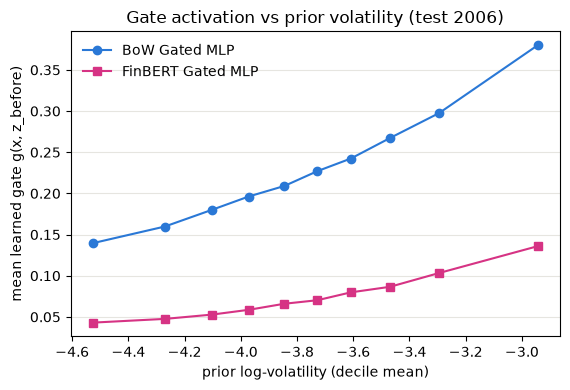

In [13]:
# Interpretability: Gate Activation vs. Prior Volatility (+ Attention Concentration if chunks loaded)
T_LAST = max(scoring.TEST_YEARS)
D_last = DIAGNOSTICS[KEY_OF[(MAIN_WINDOW, T_LAST)]]
te_idx = D_last["te_idx"]
prev_te = prev[te_idx]
bow_g = D_last["bow_gate_mean"]

n_plots = 2 if "attn_weights_mean" in D_last else 1
fig, axes = plt.subplots(1, n_plots, figsize=(5.8 * n_plots, 4.0))
if n_plots == 1:
    axes = [axes]

# Plot 1: Learned gate value vs. prior log-volatility deciles
deciles = pd.qcut(prev_te, q=10)
g_df = pd.DataFrame({"prev_logvol": prev_te, "bow_gate": bow_g, "decile": deciles})
g_summary = g_df.groupby("decile", observed=False).agg(prev_mean=("prev_logvol", "mean"), gate_mean=("bow_gate", "mean"))
axes[0].plot(g_summary["prev_mean"], g_summary["gate_mean"], "o-", color="#2a78d6", label="BoW Gated MLP")
if "fb_gate_mean" in D_last:
    g_df["fb_gate"] = D_last["fb_gate_mean"]
    g_fb = g_df.groupby("decile", observed=False).agg(prev_mean=("prev_logvol", "mean"), gate_mean=("fb_gate", "mean"))
    axes[0].plot(g_fb["prev_mean"], g_fb["gate_mean"], "s-", color="#d63384", label="FinBERT Gated MLP")
axes[0].set_xlabel("prior log-volatility (decile mean)")
axes[0].set_ylabel("mean learned gate g(x, z_before)")
axes[0].set_title(f"Gate activation vs prior volatility (test {T_LAST})")
axes[0].legend(frameon=False)
axes[0].grid(axis="y", color="#e6e5e0", lw=0.8)

# Plot 2: Attention concentration vs uniform 1/M_i (if FinBERT chunks were run)
if "attn_weights_mean" in D_last:
    w_a = D_last["attn_weights_mean"]
    n_valid = CHUNK_MASK[te_idx].sum(axis=1)
    max_w = w_a.max(axis=1)
    unif_w = 1.0 / np.maximum(n_valid, 1)
    ratio = max_w / unif_w
    axes[1].hist(ratio[n_valid >= 2], bins=30, color="#1baf7a", alpha=0.8)
    axes[1].axvline(1.0, color="#52514e", ls="--", lw=1.2, label="uniform mean-pool (ratio = 1)")
    axes[1].set_xlabel("max attention weight / uniform (1 / M_i)")
    axes[1].set_ylabel("number of reports (M_i >= 2 chunks)")
    axes[1].set_title(f"Chunk attention focus (median ratio = {np.median(ratio[n_valid >= 2]):.2f}x)")
    axes[1].legend(frameon=False)

plt.tight_layout()
plt.show()

## 6.7 — Parameter Count Comparison & Conclusions *(To Be Written After Running)*

The cell below prints the exact trainable parameter count of each architecture to verify that both models stay lightweight for this small-data regime.

In [14]:
param_rows = [
    {"architecture": f"GatedInteractionMLP (BoW, 5000 -> {HIDDEN})",
     "trainable_params": sum(p.numel() for p in GatedInteractionMLP(N_WORDS, HIDDEN, DROPOUT).parameters())},
    {"architecture": f"GatedInteractionMLP (FinBERT doc, 768 -> {HIDDEN})",
     "trainable_params": sum(p.numel() for p in GatedInteractionMLP(768, HIDDEN, DROPOUT).parameters())},
    {"architecture": f"FinBERTAttentionNet (768 chunks, attn={ATTN_DIM}, head={HIDDEN})",
     "trainable_params": sum(p.numel() for p in FinBERTAttentionNet(768, ATTN_DIM, HIDDEN, DROPOUT, use_attention=True).parameters())},
    {"architecture": f"FinBERTMeanPoolNet (768 chunks, head={HIDDEN})",
     "trainable_params": sum(p.numel() for p in FinBERTAttentionNet(768, ATTN_DIM, HIDDEN, DROPOUT, use_attention=False).parameters())},
]
pd.DataFrame(param_rows)

,architecture,trainable_params
0,"GatedInteractionMLP (BoW, 5000 -> 32)",160102
1,"GatedInteractionMLP (FinBERT doc, 768 -> 32)",24678
2,"FinBERTAttentionNet (768 chunks, attn=64, head...",73959
3,"FinBERTMeanPoolNet (768 chunks, head=32)",24678
